In [2]:
%pip install xgboost shap matplotlib

  Using cached xgboost-3.2.0-py3-none-win_amd64.whl (101.7 MB)
     -------------------------------------- 547.0/547.0 kB 3.4 MB/s eta 0:00:00
  Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
     ---------------------------------------- 2.8/2.8 MB 4.2 MB/s eta 0:00:00
     ---------------------------------------- 41.9/41.9 MB 3.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import numpy, pandas, sklearn, xgboost, shap
print("environment ok")

c:\Users\sathv\Desktop\Projects\Credit Risk Prediction\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


environment ok


# Credit Risk – Exploratory Data Analysis

**Goal:** understand the loan data, find quality problems, and see what drives default before building the model.

**Dataset:** 32,581 loan applications. Target column `loan_status`: 0 = loan repaid, 1 = loan defaulted.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("../dataset/credit_risk_dataset.csv")
print(data.shape)
data.head()

(32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 1. Data quality

Checking for missing values and impossible values before any analysis. A cleaned copy of the data (`clean`) is used for all charts below.

In [31]:
missing = data.isna().sum()
print("Missing values:")
print(pd.DataFrame({"count": missing, "percent": (missing / len(data) * 100).round(1)})[missing > 0])

print("\nImpossible values:")
print("Age over 100        :", (data["person_age"] > 100).sum())
print("Employment over 60 y:", (data["person_emp_length"] > 60).sum())
print("Income over $1M     :", (data["person_income"] > 1_000_000).sum())

# Clean copy used for all charts below
clean = data[(data["person_age"] <= 100) &
             (data["person_emp_length"].isna() | (data["person_emp_length"] <= 60))].copy()
print("\nRows kept after cleaning:", len(clean), "of", len(data))

Missing values:
                   count  percent
person_emp_length    895      2.7
loan_int_rate       3116      9.6

Impossible values:
Age over 100        : 5
Employment over 60 y: 2
Income over $1M     : 9

Rows kept after cleaning: 32574 of 32581


## 2. Target balance

How many loans default? If defaults are much rarer than repayments, accuracy becomes a misleading metric, so this decides how the model is evaluated.

Default rate: 21.8 %


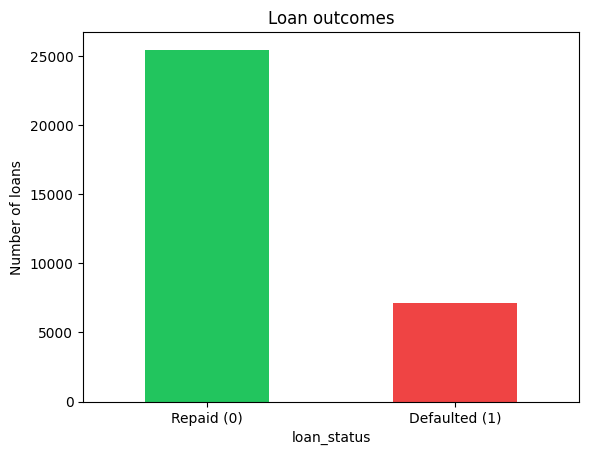

In [32]:
counts = clean["loan_status"].value_counts().sort_index()
print("Default rate:", round(clean["loan_status"].mean() * 100, 1), "%")
counts.plot(kind="bar", color=["#22c55e", "#ef4444"])
plt.xticks([0, 1], ["Repaid (0)", "Defaulted (1)"], rotation=0)
plt.title("Loan outcomes")
plt.ylabel("Number of loans")
plt.show()

## 3. Distributions

Histograms of every numeric feature. Income is clipped at the 99th percentile because a few extreme incomes (up to $6,000,000) would otherwise squash the chart into one bar.

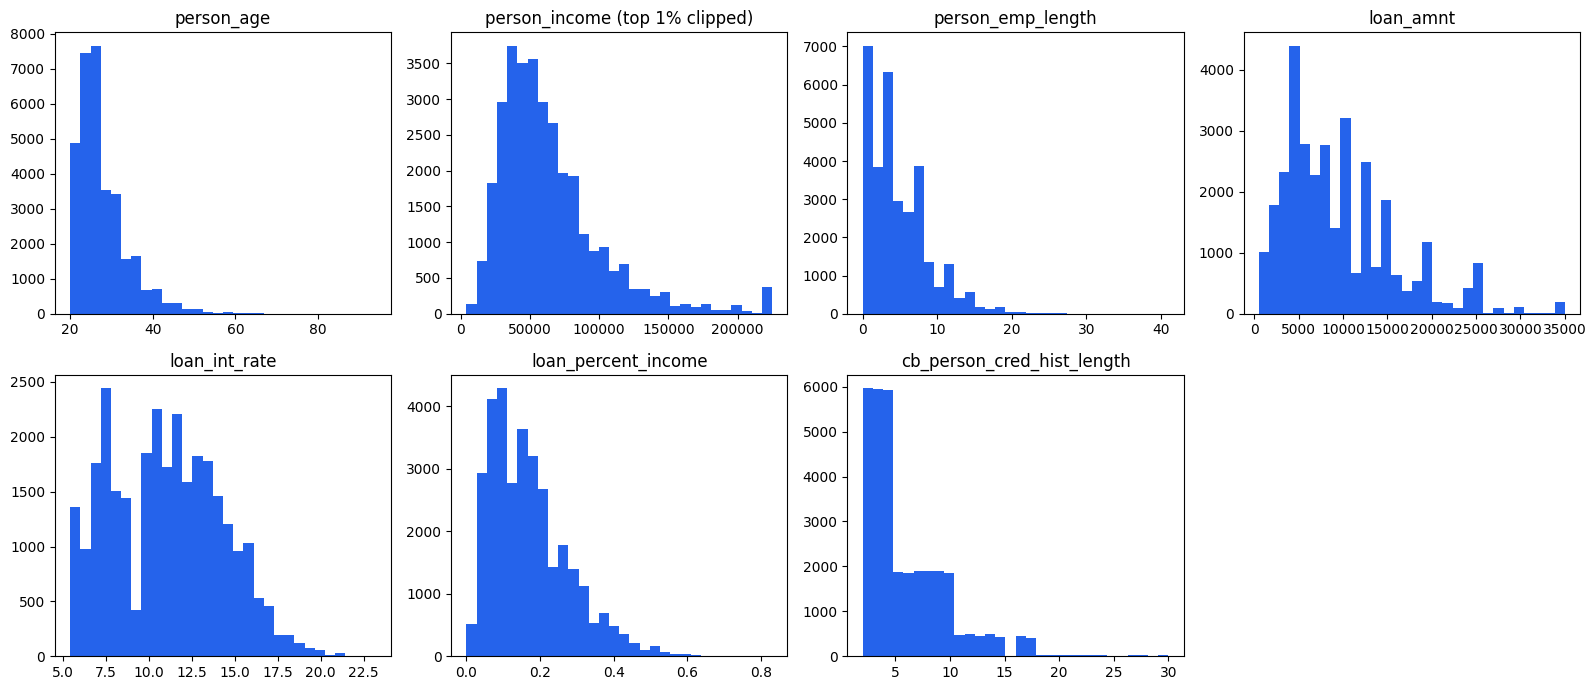

In [33]:
num_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
            "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, num_cols):
    values = clean[col].dropna()
    if col == "person_income":
        values = values.clip(upper=values.quantile(0.99))  # hide the extreme tail
        ax.set_title("person_income (top 1% clipped)")
    else:
        ax.set_title(col)
    ax.hist(values, bins=30, color="#2563eb")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## 4. What drives default?

**Category charts:** default rate for each group of loan grade, home ownership, loan intent, and previous default. The red dashed line is the overall default rate, so bars above it are riskier than average.

**Boxplots:** how interest rate, loan-to-income share, and income differ between repaid (0) and defaulted (1) loans.

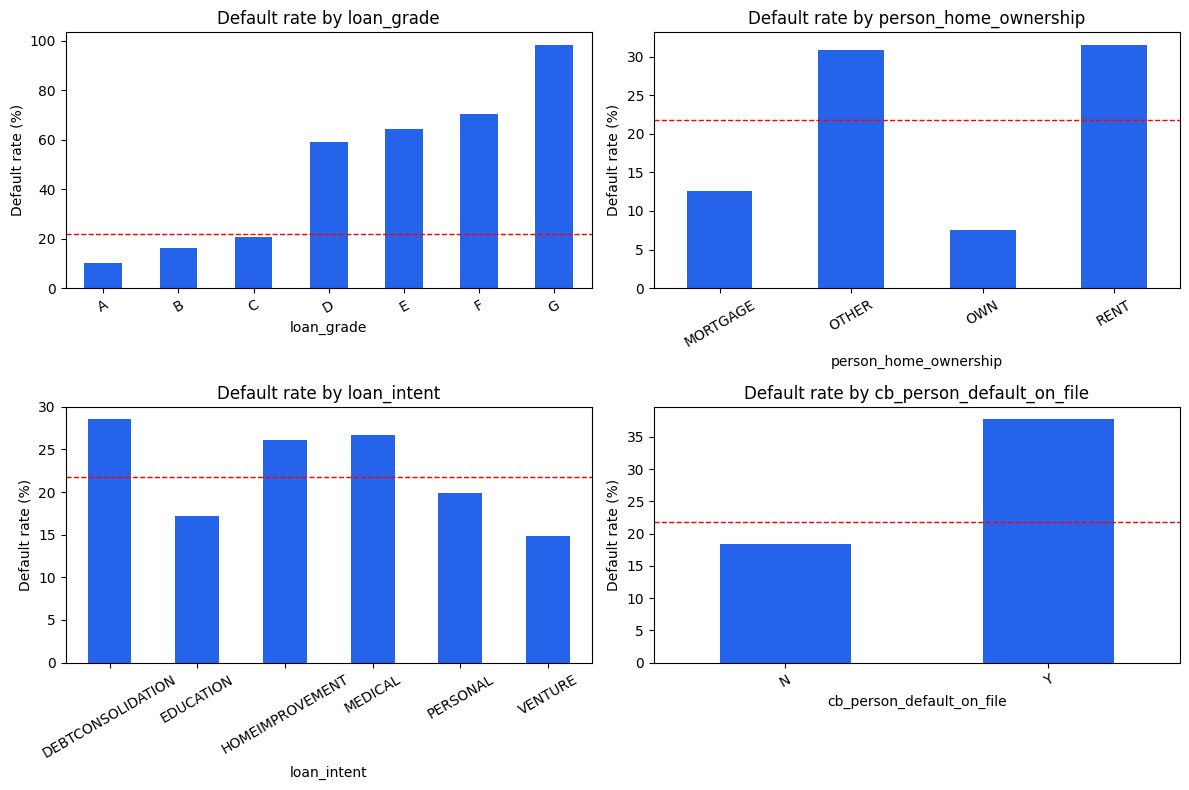

In [34]:
cat_cols = ["loan_grade", "person_home_ownership", "loan_intent", "cb_person_default_on_file"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, cat_cols):
    rate = clean.groupby(col)["loan_status"].mean().sort_index() * 100
    rate.plot(kind="bar", ax=ax, color="#2563eb")
    ax.axhline(clean["loan_status"].mean() * 100, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Default rate by {col}")
    ax.set_ylabel("Default rate (%)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

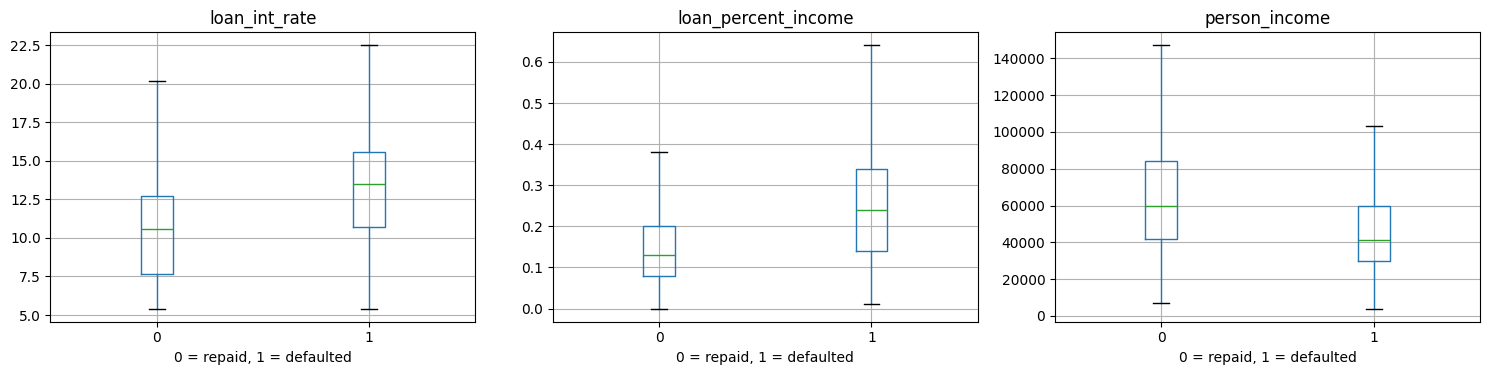

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["loan_int_rate", "loan_percent_income", "person_income"]):
    clean.boxplot(column=col, by="loan_status", ax=ax, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel("0 = repaid, 1 = defaulted")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 5. Correlations

Correlation between the numeric features, including `loan_status`. Values near +1 or -1 mean a strong linear link, and values near 0 mean little. Highly correlated features carry overlapping information.

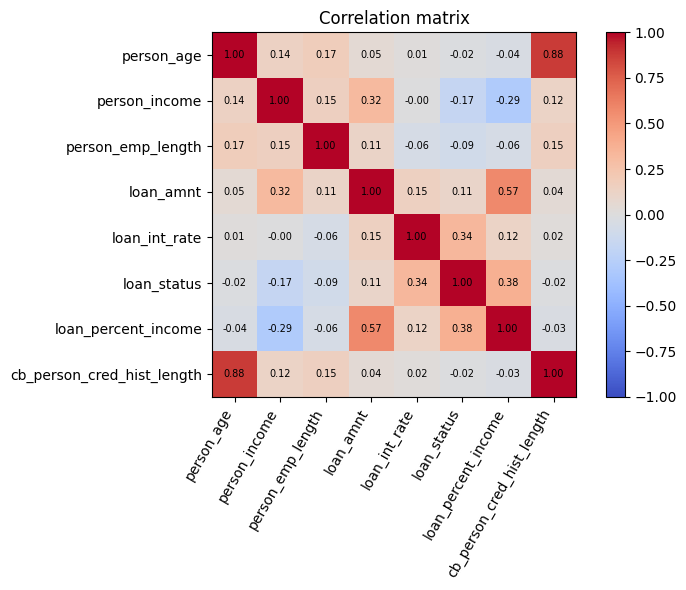

In [36]:
corr = clean.select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

## 6. Key findings

**Data quality**
- The dataset has 32,581 loans. Missing values appear in `person_emp_length` (895 rows, 2.7%) and `loan_int_rate` (3,116 rows, 9.6%); both are filled with the median during modelling.
- Some values are impossible: the maximum age is 144 and the maximum employment length is 123 years. Rows with age over 100 or employment over 60 years were removed ([N] rows, from Cell 4).
- Income reaches $6,000,000, which squashes the income histogram, so the top 1% is clipped in the chart.

**Target balance**
- 21.8% of loans default, so accuracy alone is misleading. A model that approves everyone would score about 78% accuracy while catching no defaulters. PR-AUC and recall are used instead.

**What drives default** (fill from Cells 10 and 11)
- Default rate by loan grade: [grade A is about __%, rising to about __% at grade G].
- Previous default on file: borrowers with a previous default default at [__%] versus [__%] for those without.
- Home ownership: [the group with the highest default rate is ____ at __%; the lowest is ____ at __%].
- Defaulted loans have [higher / lower] interest rates and a [higher / lower] loan-to-income share than repaid loans (boxplots).

**Correlations** (fill from Cell 13)
- The strongest link with `loan_status` is [feature, correlation __]. Loan grade drives the interest rate, so `loan_int_rate` and `loan_percent_income` overlap in what they tell the model.

**Takeaways for modelling**
- Use cleaned data, median imputation, and a stratified split so train and test keep the same default rate.
- Judge the model by PR-AUC and recall at a chosen decision threshold, not accuracy.